# Implied innovation support width from one Jones AR(3) process

The minimum-width optimizer returns both the empirical width $\widehat m_k$ and its minimizing unit direction $\widehat u_k$. Their **byproduct** is

$$
\widehat W_k=\frac{\widehat m_k}{|\widehat u_{k,0}|}
=\widehat m_k\sqrt{1+\sum_{j=1}^{k-1}(\widehat\phi_j^{(k)})^2},
\qquad \widehat\phi_j^{(k)}=-\frac{\widehat u_{k,j}}{\widehat u_{k,0}}.
$$

This experiment generates one stationary AR(3) process using the existing [Jones coefficient sampler](ar_tools/functions.py), computes $\widehat W_k$ for $k=1,\ldots,10$, and plots it against the known innovation support width $W=2$. At the population level, the unshifted minimum-width direction at $k=p+1=4$ gives $W=2$; larger dimensions also admit shifted minimizing directions with first coordinate zero [Proposition `prop:minimum_width`](../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex). The plotted values are empirical, so their behavior is illustrative rather than an order-selection guarantee.


In [1]:
import sys
from pathlib import Path

import numpy as np
from threadpoolctl import threadpool_limits

AR_DIR = next(
    candidate.resolve()
    for root in (Path.cwd(), *Path.cwd().parents)
    for candidate in (root / "Code" / "Code_AR_processes", root)
    if (candidate / "ar_tools/functions.py").is_file()
    and (candidate / "ar_tools/descent.py").is_file()
)
PROJECT_ROOT = AR_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Code.Code_AR_processes.ar_tools.functions import (
    jones_ar_coefficients,
    simulate_uniform_ar,
    sliding_window_point_cloud,
)
from Code.Code_AR_processes.ar_tools.descent import batched_geometric_width_curves

true_order = 3
sample_size = 2_000
seed = 20260816
replication = 9
k_values = np.arange(1, 11)
generator = np.random.default_rng(np.random.SeedSequence([seed, replication, 0]))
phi = jones_ar_coefficients(true_order, rng=generator)
series = simulate_uniform_ar(
    phi, sample_size=sample_size, burnin=1_000, half_width=1.0,
    rng=generator,
)

with threadpool_limits(limits=1):
    _, minimum_widths, _, minimizing_directions = batched_geometric_width_curves(
        series, k_values, seed=seed, replication=replication,
        starts=3, iterations=500, initial_step=0.2,
        geometric_decay=0.99, return_directions=True,
    )

first_coordinates = np.array([direction[0] for direction in minimizing_directions])
implied_support_widths = np.divide(
    minimum_widths,
    np.abs(first_coordinates),
    out=np.full_like(minimum_widths, np.inf),
    where=np.abs(first_coordinates) > np.finfo(float).eps,
)

print(f"Jones AR(3) coefficients: {np.array2string(phi, precision=6)}")
print(f"At k=p+1={true_order + 1}: W_hat={implied_support_widths[true_order]:.6f}; true W=2")


Jones AR(3) coefficients: [ 0.697604 -0.813994  0.642616]
At k=p+1=4: W_hat=1.999660; true W=2


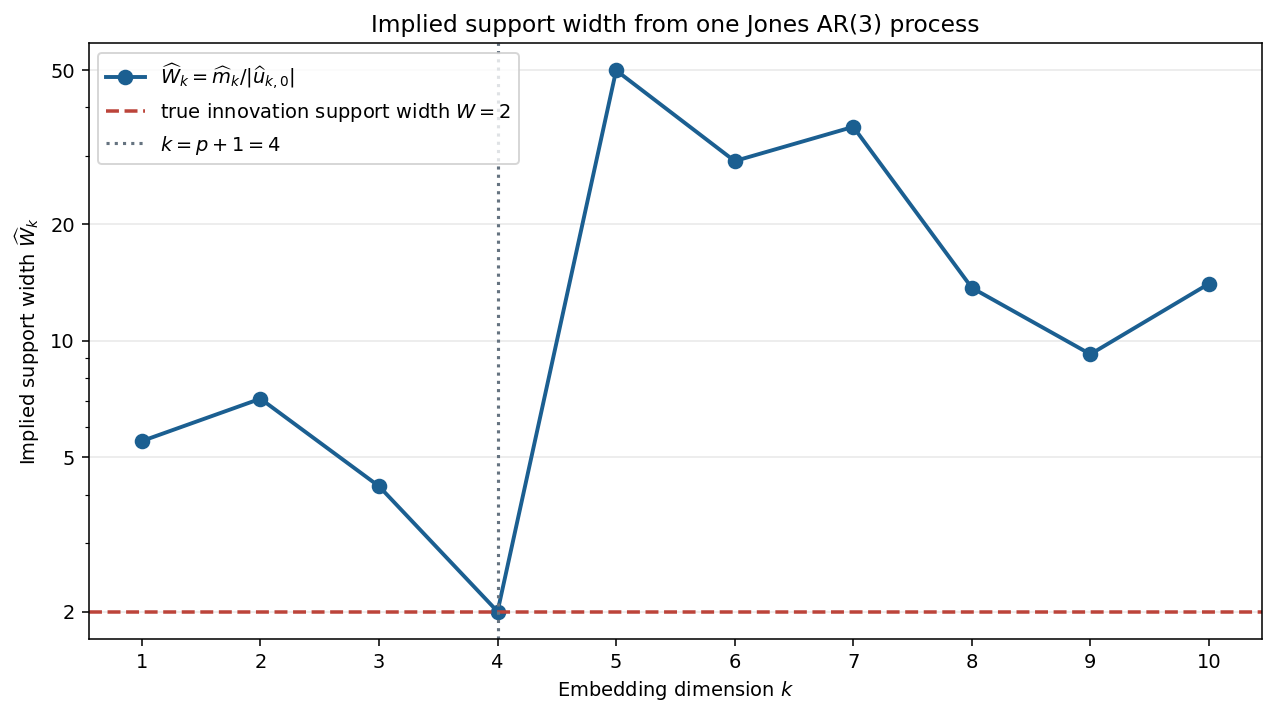

In [2]:
import matplotlib.pyplot as plt

figure, axis = plt.subplots(figsize=(9, 5), layout="constrained")
finite = np.isfinite(implied_support_widths)
axis.plot(
    k_values[finite], implied_support_widths[finite], "o-",
    color="#1b5f91", linewidth=2, markersize=7,
    label=r"$\widehat W_k=\widehat m_k/|\widehat u_{k,0}|$",
)
axis.axhline(2.0, color="#bc443a", linestyle="--", linewidth=1.8,
             label=r"true innovation support width $W=2$")
axis.axvline(true_order + 1, color="#657380", linestyle=":", linewidth=1.6,
             label=r"$k=p+1=4$")
axis.set(
    title="Implied support width from one Jones AR(3) process",
    xlabel="Embedding dimension $k$",
    ylabel=r"Implied support width $\widehat W_k$",
    xticks=k_values,
    yscale="log",
)
axis.set_yticks([2, 5, 10, 20, 50], labels=["2", "5", "10", "20", "50"])
axis.grid(axis="y", alpha=0.28)
axis.legend(loc="upper left", frameon=True)

pdf_path = AR_DIR / "outputs" / "pdfs" / "ar3_implied_support_width" / "implied_support_width.pdf"
pdf_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(pdf_path, bbox_inches="tight")
plt.show()


The ratio can become large when the optimizer returns a direction with $|\widehat u_{k,0}|$ close to zero. That is visible here beyond $k=4$; these values should not be interpreted as changes in the true innovation support. The direction and width come from the same [minimum-width optimization call](ar_tools/descent.py), with no second fit.


### Relation to set-membership identification

[Lauricella and Fagiano, *Set Membership identification of linear systems with guaranteed simulation accuracy*, §III-A–C](https://arxiv.org/html/2001.07628v2) motivate estimating an unknown bound before selecting model order. Their actual construction differs from the experiment below: equation (15) minimizes a worst-case prediction-error excess via a linear program; Procedure 1 estimates the measurement-noise bound from its behavior across *prediction horizons*; Procedure 2 decreases the candidate model order and detects a persistent positive excess using a tolerance. Here $q$ is the AR order, and $\widehat W_{q+1}$ is a residual span derived from one geometric minimum-width direction. The nearest-reference rule below is **our heuristic**, not their selector or a direct implementation of their guarantees. In particular, $\min_q\widehat W_{q+1}$ is not the bound estimator of their Procedure 1.

## Exploratory nearest-width order selection on 50 Jones AR(3) processes

For each candidate order $q=1,\ldots,9$ (embedding dimension $k=q+1$), compute $\widehat W_{q+1}$ from the empirical minimum width and its minimizing direction. Compare two selectors, resolving exact ties toward the smallest $q$:

$$
\widehat p_{\mathrm{known}}=\operatorname*{arg\,min}_{1\le q\le9}|\widehat W_{q+1}-W|,
\qquad
\widehat p_{\mathrm{direct}}=\operatorname*{arg\,min}_{1\le q\le9}\widehat W_{q+1}.
$$

The first is an **oracle benchmark** using the known simulation width $W=2$ of $\operatorname{Unif}[-1,1]$ innovations. The second requires no known reference width. Writing $\widehat W=\min_q\widehat W_{q+1}$ and minimizing $|\widehat W_{q+1}-\widehat W|$ would give exactly the same direct-argmin selector; the direct form makes clear that the estimated target supplies no independent information.

The 50 processes have independently Jones-sampled AR(3) coefficients and one length-2,000 series each. Both selectors see the same nine empirical widths and directions for every process. The theoretical relation between the unshifted minimizing direction and the innovation width follows from [Proposition `prop:minimum_width` and the following remark](../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex). The finite-sample nearest-reference rule here is an experimental choice, not a theorem.

In [3]:
import pandas as pd
from IPython.display import display

candidate_orders = np.arange(1, 10)
known_support_width = 2.0


def select_order_nearest_width(widths_by_k, reference_width):
    candidate_widths = np.asarray(widths_by_k, dtype=float)[candidate_orders]
    if not np.isfinite(reference_width) or not np.any(np.isfinite(candidate_widths)):
        raise ValueError("A finite reference and at least one finite candidate width are required.")
    # candidate_orders are ascending, so argmin resolves exact ties toward lower order.
    return int(candidate_orders[np.argmin(np.abs(candidate_widths - reference_width))])


rows = []
with threadpool_limits(limits=1):
    for process_id in range(50):
        process_rng = np.random.default_rng(np.random.SeedSequence([seed, process_id, 0]))
        coefficients = jones_ar_coefficients(true_order, rng=process_rng)
        sample = simulate_uniform_ar(
            coefficients, sample_size=sample_size, burnin=1_000,
            half_width=known_support_width / 2, rng=process_rng,
        )
        _, fitted_widths, _, fitted_directions = batched_geometric_width_curves(
            sample, k_values, seed=seed, replication=process_id,
            starts=3, iterations=500, initial_step=0.2,
            geometric_decay=0.99, return_directions=True,
        )
        first_components = np.abs([direction[0] for direction in fitted_directions])
        widths_by_k = np.divide(
            fitted_widths, first_components,
            out=np.full_like(fitted_widths, np.inf),
            where=first_components > np.finfo(float).eps,
        )
        estimated_support_width = float(np.min(widths_by_k[candidate_orders]))
        selected_order = int(candidate_orders[np.argmin(widths_by_k[candidate_orders])])
        # Diagnostic only: the true AR direction is feasible at k=4 and is never
        # supplied to either selector.
        true_direction = np.r_[1.0, -coefficients]
        true_direction /= np.linalg.norm(true_direction)
        true_cloud = sliding_window_point_cloud(sample, true_order + 1)
        feasible_width_at_true_order = np.ptp(true_cloud @ true_direction)
        feasible_implied_W = feasible_width_at_true_order / abs(true_direction[0])
        relative_objective_gap = (
            fitted_widths[true_order] - feasible_width_at_true_order
        ) / feasible_width_at_true_order
        known_order = select_order_nearest_width(widths_by_k, known_support_width)
        diagnostic_widths = widths_by_k.copy()
        diagnostic_widths[true_order] = feasible_implied_W
        known_order_with_true_direction = select_order_nearest_width(
            diagnostic_widths, known_support_width
        )
        rows.append({
            "process": process_id,
            "phi_1": coefficients[0],
            "phi_2": coefficients[1],
            "phi_3": coefficients[2],
            "estimated_W": estimated_support_width,
            "W_at_true_order": widths_by_k[true_order],
            "W_at_selected_order": widths_by_k[selected_order],
            "W_at_known_order": widths_by_k[known_order],
            "W_along_true_direction": feasible_implied_W,
            "relative_objective_gap": relative_objective_gap,
            "known_W_order": known_order,
            "known_order_with_true_direction": known_order_with_true_direction,
            "estimated_W_order": selected_order,
        })

results = pd.DataFrame(rows)
assert len(results) == 50
assert (results["estimated_W_order"].between(1, 9)).all()

def count_outcomes(selected_orders):
    return {
        "Correct": int((selected_orders == true_order).sum()),
        "Under": int((selected_orders < true_order).sum()),
        "Over": int((selected_orders > true_order).sum()),
    }

summary = pd.DataFrame.from_dict({
    r"Known $W=2$": count_outcomes(results["known_W_order"]),
    r"Plug-in $\widehat W$": count_outcomes(results["estimated_W_order"]),
}, orient="index")
summary.index.name = "Selector"
summary["Total"] = summary.sum(axis=1)
display(summary.style.set_caption("Order selection across 50 Jones AR(3) processes (true p=3)"))

order_counts = pd.DataFrame({
    "Known W": results["known_W_order"].value_counts().reindex(candidate_orders, fill_value=0),
    "Plug-in W_hat": results["estimated_W_order"].value_counts().reindex(candidate_orders, fill_value=0),
})
order_counts.index.name = "Selected order"
display(order_counts.style.set_caption("Distribution of selected orders"))

print(
    f"Plug-in support width: median={results['estimated_W'].median():.3f}, "
    f"median absolute error={np.median(np.abs(results['estimated_W'] - known_support_width)):.3f} "
    f"(true W={known_support_width:.0f})."
)


,Correct,Under,Over,Total
Selector,,,,
Known $W=2$,35,12,3,50
Plug-in $\widehat W$,34,12,4,50


,Known W,Plug-in W_hat
Selected order,,
1,5,5
2,7,7
3,35,34
4,2,1
5,1,1
6,0,1
7,0,0
8,0,1
9,0,0


Plug-in support width: median=2.007, median absolute error=0.007 (true W=2).


### Why the direct argmin fails

The next check uses the **true AR(3) coefficients only as a diagnostic**, never in either selector. At $k=4$, the normalized vector $(1,-\phi_1,-\phi_2,-\phi_3)$ is a feasible direction. If the optimizer reports a minimum width larger than the empirical width in that direction, it demonstrably missed an attainable value of its own objective. A relative gap above 1% is marked as a material miss. Separately, compare the implied width at the selected order with that of the feasible true direction: if the latter is smaller, substituting only that direction would reverse the direct-argmin decision. This counterfactual does not claim that a practical optimizer would find that direction. The population role of this direction follows from [Proposition `prop:minimum_width`](../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex).

In [4]:
failures = results.loc[results["estimated_W_order"] != true_order].copy()
failures["error"] = np.where(failures["estimated_W_order"] < true_order, "Under", "Over")
failures["material_optimizer_miss"] = failures["relative_objective_gap"] > 0.01
failures["feasible_direction_wins"] = (
    failures["W_along_true_direction"] < failures["W_at_selected_order"]
)

failure_summary = pd.DataFrame([
    {
        "Error": error,
        "Count": len(group),
        "Material optimizer misses": int(group["material_optimizer_miss"].sum()),
        "Feasible AR(3) direction wins": int(group["feasible_direction_wins"].sum()),
        "Median |phi_3|": group["phi_3"].abs().median(),
    }
    for error, group in failures.groupby("error", sort=False)
]).set_index("Error")
display(failure_summary.style.format({"Median |phi_3|": "{:.3f}"}).set_caption(
    "Direct-argmin failures and diagnostics; 1% cutoff for material optimization miss"
))

display(
    failures[[
        "process", "error", "estimated_W_order", "phi_3",
        "W_at_selected_order", "W_at_true_order", "W_along_true_direction",
        "relative_objective_gap",
    ]].sort_values("process").style.format({
        "phi_3": "{:.3f}",
        "W_at_selected_order": "{:.3f}",
        "W_at_true_order": "{:.3f}",
        "W_along_true_direction": "{:.3f}",
        "relative_objective_gap": "{:.1%}",
    }).set_caption("All 16 failed selections; true coefficients used for diagnosis only")
)

# Re-run k=4 with a larger random-start budget for the failures, without
# supplying the true direction. The other candidate widths remain unchanged.
more_starts_wins = []
with threadpool_limits(limits=1):
    for failed in failures.itertuples():
        rng = np.random.default_rng(np.random.SeedSequence([seed, failed.process, 0]))
        phi = jones_ar_coefficients(true_order, rng=rng)
        sample = simulate_uniform_ar(
            phi, sample_size=sample_size, burnin=1_000,
            half_width=known_support_width / 2, rng=rng,
        )
        _, widths4, _, directions4 = batched_geometric_width_curves(
            sample, [true_order + 1], seed=seed, replication=failed.process,
            starts=20, iterations=1_000, initial_step=0.2,
            geometric_decay=0.99, return_directions=True,
        )
        u0 = abs(directions4[0][0])
        new_implied_W4 = widths4[0] / u0 if u0 > np.finfo(float).eps else np.inf
        more_starts_wins.append(new_implied_W4 < failed.W_at_selected_order)

print(
    f"With 20 starts and 1,000 iterations at k=4, its implied width beats "
    f"the previously selected candidate in {sum(more_starts_wins)}/{len(failures)} "
    "failed cases. This is a diagnostic rerun, not a revised selector."
)


,Count,Material optimizer misses,Feasible AR(3) direction wins,Median |phi_3|
Error,,,,
Over,4,1,1,0.250
Under,12,11,11,0.163


,process,error,estimated_W_order,phi_3,W_at_selected_order,W_at_true_order,W_along_true_direction,relative_objective_gap
0,0,Over,4,0.602,2.013,113.579,1.999,51.5%
1,1,Under,2,0.163,2.393,3.344,1.999,7.1%
2,2,Under,2,0.163,2.325,3.777,1.999,15.0%
4,4,Under,2,-0.083,2.154,2.936,1.998,4.8%
5,5,Over,6,-0.222,1.995,1.997,1.999,-0.1%
7,7,Over,5,-0.175,1.994,1.995,1.997,-0.2%
8,8,Under,2,0.353,2.916,22.141,1.998,8.8%
11,11,Under,1,-0.120,2.240,58.564,2.000,11.3%
14,14,Under,1,0.302,2.699,937.665,1.999,34.8%
15,15,Under,1,-0.174,2.731,108.684,1.998,15.0%


With 20 starts and 1,000 iterations at k=4, its implied width beats the previously selected candidate in 6/16 failed cases. This is a diagnostic rerun, not a revised selector.


The failure counts show why the aggregate 34/50 figure is misleading. Most errors are underselections associated with a clear miss of a feasible $k=4$ direction. Some overselected cases instead have nearly indistinguishable implied widths around $W=2$, so a bare argmin rewards very small empirical differences. Even an improved normalized-width objective need not improve the ratio $\widehat m_k/|\widehat u_{k,0}|$: the direction chosen by the geometric optimizer, particularly its first coordinate, is part of the order-selection problem.

### Why knowing $W$ did not solve the problem

The known-$W$ selector still uses the optimizer's chosen direction at every order. The following counterfactual replaces only its $k=4$ implied width by the empirical residual span along the *true* AR(3) direction, retaining every other fitted candidate width and the same nearest-to-$W=2$ rule. It diagnoses the importance of the $k=4$ direction; it is not an implementable order selector because it uses the unknown coefficients.

In [5]:
known_failures = results.loc[results["known_W_order"] != true_order].copy()
known_failures["error"] = np.where(
    known_failures["known_W_order"] < true_order, "Under", "Over"
)
known_failure_summary = pd.DataFrame([
    {
        "Error": error,
        "Count": len(group),
        "Material optimizer misses": int((group["relative_objective_gap"] > 0.01).sum()),
        "Corrected by true-direction substitution": int(
            (group["known_order_with_true_direction"] == true_order).sum()
        ),
    }
    for error, group in known_failures.groupby("error", sort=False)
]).set_index("Error")
display(known_failure_summary.style.set_caption(
    "Known-W selector failures (true p=3; true direction used only for diagnosis)"
))

changed_decisions = results.loc[
    results["known_W_order"] != results["estimated_W_order"],
    ["process", "known_W_order", "estimated_W_order", "W_at_true_order"],
]
display(changed_decisions.style.format({"W_at_true_order": "{:.6f}"}).set_caption(
    "The four processes whose two selectors choose different orders"
))

print(
    f"A feasible true AR(3) direction would correct "
    f"{int((known_failures['known_order_with_true_direction'] == true_order).sum())}/"
    f"{len(known_failures)} known-W failures; the counterfactual selects p=3 in "
    f"{int((results['known_order_with_true_direction'] == true_order).sum())}/50 overall."
)


,Count,Material optimizer misses,Corrected by true-direction substitution
Error,,,
Over,3,1,2
Under,12,11,12


,process,known_W_order,estimated_W_order,W_at_true_order
5,5,5,6,1.997407
7,7,3,5,1.995207
16,16,4,3,1.999484
36,36,3,8,1.997407


A feasible true AR(3) direction would correct 14/15 known-W failures; the counterfactual selects p=3 in 49/50 overall.


Knowledge of the innovation width is therefore not the dominant missing ingredient in this experiment. The large losses are mostly associated with failing to recover a useful $k=4$ direction, while the nearest-to-$W$ rule can still switch to a higher order for a tiny finite-sample difference. The counterfactual uses oracle coefficients solely to locate the failure; it does not establish the performance of an attainable improved optimizer.